# 🥊 Predicting the Winner of a Boxing Match

Given two boxers' physical attributes and professional records, can we predict who wins:
**Fighter A**, **Fighter B**, or a **draw**?

This notebook works through the full pipeline:

1. Load and explore ~387k professional boxing bouts
2. Clean the data and engineer matchup features
3. Train and compare several classifiers against a naive baseline
4. Look at what the model has actually learned
5. Use the model to predict a real fight

**Dataset:** [Boxing Matches, Kaggle (mexwell)](https://www.kaggle.com/datasets/mexwell/boxing-matches), scraped from BoxRec.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

DATA_PATH = Path("../data/boxing_matches.csv")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

## 1. Load & explore

In [2]:
matches = pd.read_csv(DATA_PATH)
print(f"{len(matches):,} bouts × {matches.shape[1]} columns")
matches.head()

387,427 bouts × 26 columns


,age_A,age_B,height_A,height_B,reach_A,reach_B,stance_A,stance_B,weight_A,weight_B,...,kos_A,kos_B,result,decision,judge1_A,judge1_B,judge2_A,judge2_B,judge3_A,judge3_B
0,35.0,27.0,179.0,175.0,178.0,179.0,orthodox,orthodox,160.0,160.0,...,33,34.0,draw,SD,110.0,118.0,115.0,113.0,114.0,114.0
1,26.0,31.0,175.0,185.0,179.0,185.0,orthodox,orthodox,164.0,164.0,...,34,32.0,win_A,UD,120.0,108.0,120.0,108.0,120.0,108.0
2,28.0,26.0,176.0,175.0,NaN,179.0,orthodox,orthodox,154.0,154.0,...,13,33.0,win_B,KO,NaN,NaN,NaN,NaN,NaN,NaN
3,25.0,29.0,175.0,174.0,179.0,180.0,orthodox,orthodox,155.0,155.0,...,32,19.0,win_A,KO,47.0,48.0,49.0,46.0,48.0,47.0
4,25.0,35.0,175.0,170.0,179.0,170.0,orthodox,orthodox,155.0,NaN,...,32,33.0,win_A,UD,118.0,110.0,119.0,109.0,117.0,111.0


### Missing values
Physical stats are patchy, especially reach and anything about Fighter B. Lots of lower-level
fighters on BoxRec don't have their reach or height recorded.

In [3]:
missing = matches.isnull().mean().sort_values(ascending=False)
missing[missing > 0].to_frame("fraction missing").style.format("{:.1%}")

,fraction missing
reach_B,90.2%
judge1_B,86.6%
judge1_A,86.5%
judge3_B,84.2%
judge3_A,84.2%
judge2_B,81.9%
judge2_A,81.8%
reach_A,71.0%
weight_B,66.4%
height_B,65.2%


### The target is heavily imbalanced
Fighter A wins **83%** of bouts. In this dataset Fighter A is the boxer whose BoxRec page the bout
was scraped from, and those boxers tend to be the more established, often home, fighter.

This matters a lot: **a "model" that always predicts Fighter A is already 83% accurate.**
So we need metrics that reward getting the *minority* outcomes right too.

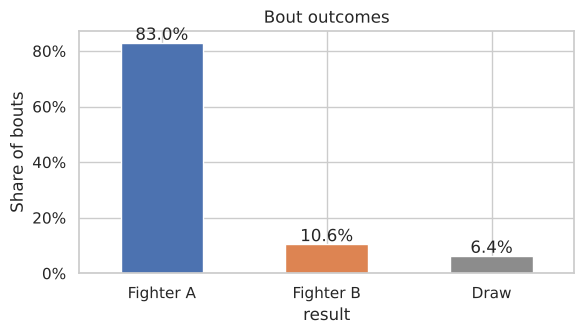

In [4]:
labels = {"win_A": "Fighter A", "win_B": "Fighter B", "draw": "Draw"}
fig, ax = plt.subplots(figsize=(6, 3.5))
counts = matches["result"].map(labels).value_counts(normalize=True)
counts.plot.bar(ax=ax, color=["#4C72B0", "#DD8452", "#8C8C8C"], rot=0)
ax.set_ylabel("Share of bouts")
ax.set_title("Bout outcomes")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for i, v in enumerate(counts):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.savefig(IMAGES / "class_balance.png", dpi=150)
plt.show()

## 2. Feature engineering

Each bout is turned into **matchup features** describing how the two fighters compare.

| Feature | Meaning |
|---|---|
| `age_diff`, `height_diff`, `reach_diff`, `weight_diff` | Physical advantage of A over B |
| `win_rate_*`, `loss_rate_*`, `ko_rate_*` | Each fighter's record as rates |
| `experience_*`, `experience_diff` | Total professional bouts |
| `southpaw_*` | Whether each fighter fights southpaw |

**Avoiding leakage:** `decision` and the judges' scorecards are only known *after* the fight, so
they are excluded from the features.

**Missing values:** Gradient boosting handles `NaN` natively. For the other models we impute with
the median rather than filling with 0, because a fighter with "age 0" or "reach 0" would be nonsense.

In [5]:
def rate(numerator, denominator):
    """Safe division that returns NaN when a fighter has no recorded bouts."""
    return numerator / denominator.replace(0, np.nan)


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    f = pd.DataFrame(index=df.index)
    for s in ("A", "B"):
        bouts = df[f"won_{s}"] + df[f"lost_{s}"] + df[f"drawn_{s}"]
        f[f"experience_{s}"] = bouts
        f[f"win_rate_{s}"] = rate(df[f"won_{s}"], bouts)
        f[f"loss_rate_{s}"] = rate(df[f"lost_{s}"], bouts)
        f[f"ko_rate_{s}"] = rate(df[f"kos_{s}"], bouts).clip(upper=1)  # a few scraped records have KOs > bouts
        f[f"southpaw_{s}"] = (df[f"stance_{s}"] == "southpaw").astype(float).where(df[f"stance_{s}"].notna())
    for col in ("age", "height", "reach", "weight"):
        f[f"{col}_diff"] = df[f"{col}_A"] - df[f"{col}_B"]
    f["experience_diff"] = f["experience_A"] - f["experience_B"]
    f["win_rate_diff"] = f["win_rate_A"] - f["win_rate_B"]
    f["ko_rate_diff"] = f["ko_rate_A"] - f["ko_rate_B"]
    return f


X = build_features(matches)
y = matches["result"].map(labels)
print(f"{X.shape[1]} features")
X.describe().T.round(2)

17 features


,count,mean,std,min,25%,50%,75%,max
experience_A,387427.0,31.42,38.08,0.0,6.00,18.00,42.00,459.0
win_rate_A,369132.0,0.77,0.22,0.0,0.66,0.81,0.96,1.0
loss_rate_A,369132.0,0.16,0.18,0.0,0.00,0.12,0.23,1.0
ko_rate_A,369132.0,0.40,0.27,0.0,0.19,0.36,0.58,1.0
southpaw_A,231009.0,0.18,0.38,0.0,0.00,0.00,0.00,1.0
experience_B,387427.0,26.41,31.70,0.0,5.00,17.00,36.00,674.0
win_rate_B,354472.0,0.52,0.28,0.0,0.33,0.55,0.74,1.0
loss_rate_B,354472.0,0.39,0.29,0.0,0.17,0.33,0.56,1.0
ko_rate_B,354393.0,0.24,0.22,0.0,0.06,0.19,0.36,1.0
southpaw_B,231009.0,0.18,0.38,0.0,0.00,0.00,0.00,1.0


## 3. Train & compare models

We use a stratified 80/20 split, so both halves keep the same 83 / 11 / 6 outcome mix.

We report three metrics:
- **Accuracy:** looks great for everything because of the imbalance
- **Balanced accuracy:** the average recall across the three outcomes (chance = 33%)
- **Macro F1:** treats Fighter A wins, Fighter B wins and draws as equally important

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

models = {
    "Baseline (always Fighter A)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=150, min_samples_leaf=20, class_weight="balanced",
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.08, class_weight="balanced", random_state=RANDOM_STATE
    ),
}

results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
    })

results = pd.DataFrame(results).set_index("Model")
results.style.format("{:.1%}").highlight_max(color="#c6efce", subset=["Balanced accuracy", "Macro F1"])

,Accuracy,Balanced accuracy,Macro F1
Model,,,
Baseline (always Fighter A),83.0%,33.3%,30.2%
Logistic Regression,56.9%,52.9%,41.2%
Random Forest,62.6%,55.7%,45.0%
Gradient Boosting,61.0%,54.9%,43.9%


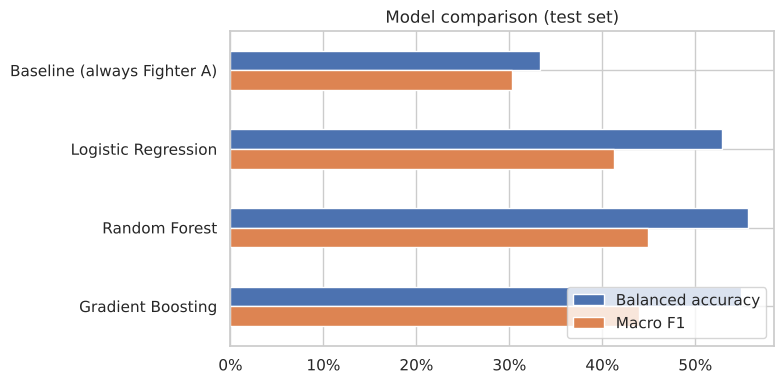

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
results[["Balanced accuracy", "Macro F1"]].plot.barh(ax=ax, color=["#4C72B0", "#DD8452"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Model comparison (test set)")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMAGES / "model_comparison.png", dpi=150)
plt.show()

### Best model in detail

Best model: Random Forest



              precision    recall  f1-score   support

        Draw      0.157     0.449     0.233      4954
   Fighter A      0.924     0.646     0.761     64333
   Fighter B      0.257     0.576     0.355      8199

    accuracy                          0.626     77486
   macro avg      0.446     0.557     0.450     77486
weighted avg      0.805     0.626     0.684     77486



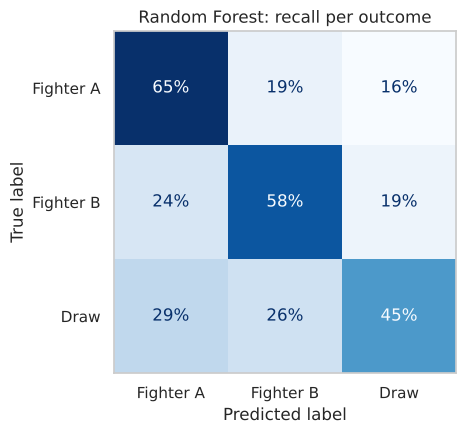

In [8]:
best_name = results["Macro F1"].idxmax()
best = models[best_name]
print(f"Best model: {best_name}\n")
print(classification_report(y_test, predictions[best_name], digits=3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_name], normalize="true", values_format=".0%",
    labels=["Fighter A", "Fighter B", "Draw"], cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title(f"{best_name}: recall per outcome")
ax.grid(False)
plt.tight_layout()
plt.savefig(IMAGES / "confusion_matrix.png", dpi=150)
plt.show()

## 4. What drives the predictions?

Permutation importance measures how much macro F1 drops when a feature's values are shuffled,
which breaks that feature's link to the outcome. We compute it on a 20k-bout sample of the test set to keep it quick.

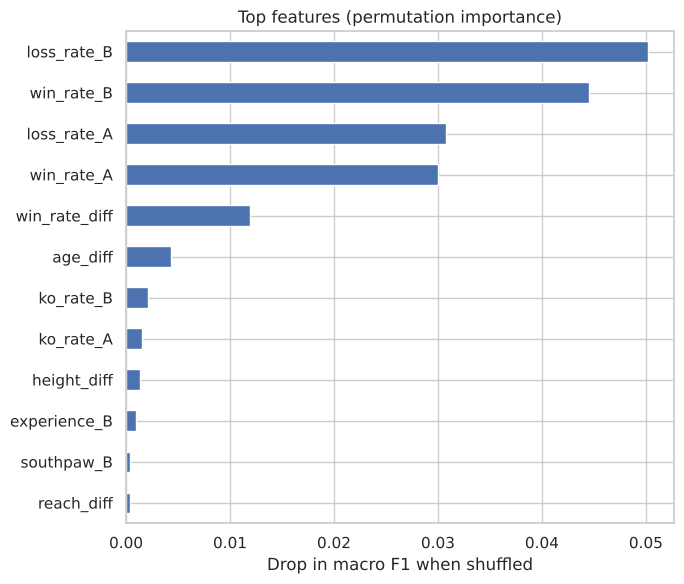

In [9]:
sample = X_test.sample(20_000, random_state=RANDOM_STATE)
imp = permutation_importance(
    best, sample, y_test.loc[sample.index], scoring="f1_macro",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
importance.tail(12).plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Top features (permutation importance)")
ax.set_xlabel("Drop in macro F1 when shuffled")
plt.tight_layout()
plt.savefig(IMAGES / "feature_importance.png", dpi=150)
plt.show()

## 5. Predict a fight

`predict_fight` takes two fighters' stats and returns the model's probabilities for each outcome.
As an example we use **Chris Eubank Jr vs Conor Benn** (April 2025), with approximate stats from
before the fight.

In [10]:
def predict_fight(a: dict, b: dict, model=best) -> pd.Series:
    """a / b: dicts with age, height (cm), reach (cm), weight (lbs), won, lost, drawn, kos, stance."""
    row = {}
    for s, f in (("A", a), ("B", b)):
        for k in ("age", "height", "reach", "weight", "won", "lost", "drawn", "kos", "stance"):
            row[f"{k}_{s}"] = f.get(k, np.nan)
    feats = build_features(pd.DataFrame([row]))
    return pd.Series(model.predict_proba(feats)[0], index=model.classes_).sort_values(ascending=False)


eubank_jr = dict(age=35, height=180, reach=184, weight=160, won=34, lost=3, drawn=0, kos=25, stance="orthodox")
benn = dict(age=28, height=173, reach=173, weight=160, won=23, lost=0, drawn=0, kos=14, stance="orthodox")

probs = predict_fight(eubank_jr, benn)
probs.to_frame("Probability").style.format("{:.1%}")

,Probability
Fighter B,72.9%
Fighter A,17.0%
Draw,10.1%


**The model picked Benn, and Benn lost.** Eubank Jr won the real fight on the scorecards.

That's a useful failure. The model leans heavily on win and loss rates, and Benn's unbeaten 23-0
record looks better on paper than Eubank Jr's 34-3. What the features can't see is *who* those wins came
against, or that Benn was moving up in weight. Opponent-quality features would be the obvious next improvement.

## 6. Takeaways & limitations

- **Beating the baseline is the real test.** Plain accuracy is misleading here: always predicting
  Fighter A scores ~83%. Our first versions of this project reported 74 to 79% accuracy, which is
  actually *worse* than doing nothing. Balanced accuracy and macro F1 show whether a model has learned anything.
- **Records dominate.** Win rate, loss rate and experience carry most of the signal. Physical
  differences such as reach and height matter much less, partly because they are often missing.
- **Draws are close to unpredictable** from pre-fight stats. That makes sense, since a draw is close to a coin flip on the judges' cards.
- **Possible leakage in the records:** BoxRec records may reflect each fighter's record when the
  data was scraped, not at the time of the bout. A stricter version would rebuild each fighter's
  record as of the fight date.
- **Next steps:** time-aware train/test split, Elo-style ratings, opponent-quality features, and a
  small web app front end for `predict_fight`.